# 01 — Pemahaman & Persiapan Data (Data Understanding)

## Tujuan
- Memahami struktur, dimensi, tipe data, dan kualitas dataset mentah Bondora (`LoanData.csv`).
- Mengidentifikasi duplikat, *missing values*, kolom konstan/berkardinalitas tinggi, distribusi numerik/kategorikal, dan rentang tanggal.
- Menyusun draf kamus data (`data_dictionary_draft.csv`) dan tabel *missing values* (`missing_values.csv`) sebagai dasar pengambilan keputusan pada **Gerbang 1** dan **Gerbang 2**.

## Input / Output
- **Input:** `data/raw/LoanData.csv` (bersifat *read-only*)
- **Output Bagian A:**
  - `reports/tables/missing_values.csv`
  - `reports/tables/data_dictionary_draft.csv`
  - `reports/figures/01_missing_values_histogram.png`

---
## Bagian A — Inspeksi Awal Dataset Mentah

### A.1 Setup & Dimensi Dataset
Memuat dataset menggunakan fungsi `load_raw()` dari `src.data.loader` dan memeriksa jumlah baris, jumlah kolom, serta konsumsi memori.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import (
    DATA_RAW,
    FIGURES_DIR,
    LOANDATA_FILENAME,
    RANDOM_SEED,
    TABLES_DIR,
    ensure_dirs,
)
from src.data.loader import describe_schema, load_raw

ensure_dirs()
df = load_raw()

n_rows, n_cols = df.shape
mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)
file_size_mb = (DATA_RAW / LOANDATA_FILENAME).stat().st_size / (1024 * 1024)

print(f"Jumlah baris         : {n_rows:,}")
print(f"Jumlah kolom         : {n_cols}")
print(f"Ukuran file CSV (MB) : {file_size_mb:.2f} MB")
print(f"Ukuran memori DataFrame: {mem_mb:.2f} MB")

[load_raw] Successfully loaded 'LoanData.csv' using encoding='utf-8' (shape=179,235 rows x 112 cols).
Jumlah baris         : 179,235
Jumlah kolom         : 112
Ukuran file CSV (MB) : 142.66 MB
Ukuran memori DataFrame: 190.94 MB


### A.2 Daftar Kolom & Skema Awal (`describe_schema`)
Menampilkan seluruh kolom beserta tipe data (`dtype`), jumlah & persentase *missing*, jumlah nilai unik, dan 3 contoh nilai non-null pertama.

In [2]:
schema_df = describe_schema(df)
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 160, "display.max_colwidth", 50):
    print(schema_df.to_string(index=False))

                            nama_kolom   dtype  n_missing  pct_missing  n_unique                                                                                                       contoh_nilai
                         ReportAsOfEOD     str          0       0.0000         1                                                                               2021-07-20 | 2021-07-20 | 2021-07-20
                                LoanId     str          0       0.0000    179235 66AE108B-532B-4BB3-BAB7-0019A46412C1 | D152382E-A50D-46ED-8FF2-0053E0C86A70 | 87342E13-66CB-483F-833A-007953E50C78
                            LoanNumber   int64          0       0.0000    179235                                                                                           483449 | 378148 | 451831
                           ListedOnUTC     str          0       0.0000    178456                                                    2016-03-23 16:07:19 | 2015-06-25 11:02:28 | 2016-01-14 10:00:21
                    

### A.3 Sampel Data: 5 Baris Pertama & 5 Baris Acak
Menampilkan 5 baris pertama (`df.head(5)`) dan 5 baris acak dengan `random_state=RANDOM_SEED` (`42`).

In [3]:
with pd.option_context("display.max_columns", 20, "display.width", 140):
    print("=== 5 Baris Pertama (df.head(5)) ===")
    print(df.head(5).to_string())
    print(f"\n=== 5 Baris Acak (df.sample(5, random_state={RANDOM_SEED})) ===")
    print(df.sample(5, random_state=RANDOM_SEED).to_string())

=== 5 Baris Pertama (df.head(5)) ===
  ReportAsOfEOD                                LoanId  LoanNumber          ListedOnUTC     BiddingStartedOn  BidsPortfolioManager  BidsApi  BidsManual   UserName  NewCreditCustomer LoanApplicationStartedDate    LoanDate ContractEndDate FirstPaymentDate MaturityDate_Original MaturityDate_Last  ApplicationSignedHour  ApplicationSignedWeekday  VerificationType  LanguageCode  Age  DateOfBirth  Gender Country  AppliedAmount  Amount  Interest  LoanDuration  MonthlyPayment  County  City  UseOfLoan  Education  MaritalStatus NrOfDependants  EmploymentStatus EmploymentDurationCurrentEmployer  EmploymentPosition   WorkExperience  OccupationArea  HomeOwnershipType  IncomeFromPrincipalEmployer  IncomeFromPension  IncomeFromFamilyAllowance  IncomeFromSocialWelfare  IncomeFromLeavePay  IncomeFromChildSupport  IncomeOther  IncomeTotal  ExistingLiabilities  LiabilitiesTotal  RefinanceLiabilities  DebtToIncome  FreeCash  MonthlyPaymentDay  ActiveScheduleFirstPaymentR

### A.4 Pemeriksaan Duplikat
Memeriksa: (a) baris yang identik penuh di seluruh kolom, dan (b) duplikat pada kandidat kolom pengenal (*identifier*).

In [4]:
n_full_dup = int(df.duplicated().sum())
print(f"(a) Jumlah baris duplikat identik penuh (df.duplicated().sum()): {n_full_dup:,}\n")
print("(b) Pemeriksaan kandidat kolom pengenal (ID):")
for col in df.columns:
    if any(k in col.lower() for k in ["id", "number", "username"]):
        n_miss = int(df[col].isna().sum())
        n_uniq = int(df[col].nunique(dropna=True))
        n_dup_nonnull = int(df[col].dropna().duplicated().sum())
        print(
            f"  - {col:<25}: dtype={df[col].dtype}, n_unique={n_uniq:,}, "
            f"n_missing={n_miss:,}, duplikat (non-null)={n_dup_nonnull:,}"
        )

(a) Jumlah baris duplikat identik penuh (df.duplicated().sum()): 0

(b) Pemeriksaan kandidat kolom pengenal (ID):
  - LoanId                   : dtype=str, n_unique=179,235, n_missing=0, duplikat (non-null)=0
  - LoanNumber               : dtype=int64, n_unique=179,235, n_missing=0, duplikat (non-null)=0
  - BiddingStartedOn         : dtype=str, n_unique=178,462, n_missing=0, duplikat (non-null)=773
  - BidsPortfolioManager     : dtype=int64, n_unique=5,803, n_missing=0, duplikat (non-null)=173,432
  - BidsApi                  : dtype=int64, n_unique=1,286, n_missing=0, duplikat (non-null)=177,949
  - BidsManual               : dtype=float64, n_unique=4,461, n_missing=0, duplikat (non-null)=174,774
  - UserName                 : dtype=str, n_unique=85,087, n_missing=0, duplikat (non-null)=94,148


### A.5 Analisis Missing Values
Mengurutkan kolom berdasarkan persentase *missing* tertinggi, menyimpan tabel ke `reports/tables/missing_values.csv`, dan menampilkan histogram distribusi persentase *missing*.

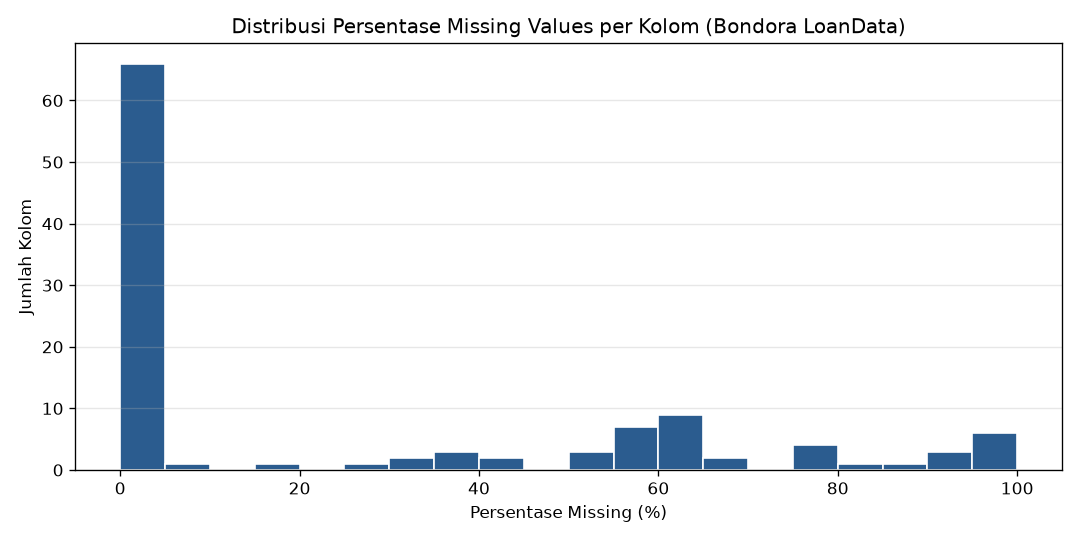

Disimpan ke: reports\tables\missing_values.csv
Total kolom dengan missing > 0%  : 69 dari 112 kolom
Kolom dengan missing > 50%       : 36 kolom
Kolom dengan missing > 80%       : 11 kolom
Kolom dengan missing > 90%       : 9 kolom
Kolom dengan missing > 95%       : 6 kolom

                            nama_kolom   dtype  n_missing  pct_missing  n_unique
                                  City float64     179235     100.0000         0
                                County float64     179235     100.0000         0
                           DateOfBirth float64     179235     100.0000         0
                    EmploymentPosition float64     179235     100.0000         0
                                 EL_V0 float64     174666      97.4508      1203
                             Rating_V0     str     174666      97.4508         8
              CreditScoreEsEquifaxRisk     str     167016      93.1827         6
                                 EL_V1 float64     166311      92.7894      1

In [5]:
missing_df = (
    schema_df[["nama_kolom", "dtype", "n_missing", "pct_missing", "n_unique"]]
    .sort_values(by=["pct_missing", "nama_kolom"], ascending=[False, True])
    .reset_index(drop=True)
)
missing_csv_path = TABLES_DIR / "missing_values.csv"
missing_df.to_csv(missing_csv_path, index=False, encoding="utf-8")

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)
ax.hist(missing_df["pct_missing"], bins=20, color="#2b5c8f", edgecolor="white")
ax.set_title("Distribusi Persentase Missing Values per Kolom (Bondora LoanData)")
ax.set_xlabel("Persentase Missing (%)")
ax.set_ylabel("Jumlah Kolom")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_missing_values_histogram.png")
plt.show()

with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 140):
    print(f"Disimpan ke: {missing_csv_path.relative_to(project_root)}")
    print(f"Total kolom dengan missing > 0%  : {(missing_df['n_missing'] > 0).sum()} dari {n_cols} kolom")
    print(f"Kolom dengan missing > 50%       : {(missing_df['pct_missing'] > 50).sum()} kolom")
    print(f"Kolom dengan missing > 80%       : {(missing_df['pct_missing'] > 80).sum()} kolom")
    print(f"Kolom dengan missing > 90%       : {(missing_df['pct_missing'] > 90).sum()} kolom")
    print(f"Kolom dengan missing > 95%       : {(missing_df['pct_missing'] > 95).sum()} kolom\n")
    print(missing_df.to_string(index=False))

### A.6 Kolom Konstan & Kolom Berkardinalitas Sangat Tinggi
Mengidentifikasi kolom yang hanya memiliki $\le 1$ nilai unik (konstan) dan kolom dengan kardinalitas sangat tinggi ($> 1.000$ nilai unik).

In [6]:
const_cols = schema_df[schema_df["n_unique"] <= 1]
high_card_cols = schema_df[schema_df["n_unique"] > 1000].sort_values(by="n_unique", ascending=False)
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 140):
    print(f"=== Kolom Konstan (n_unique <= 1): {len(const_cols)} kolom ===")
    print(const_cols.to_string(index=False) if len(const_cols) > 0 else "Tidak ada kolom dengan n_unique <= 1.")
    print(f"\n=== Kolom Berkardinalitas Sangat Tinggi (n_unique > 1.000): {len(high_card_cols)} kolom ===")
    print(high_card_cols.to_string(index=False))

=== Kolom Konstan (n_unique <= 1): 5 kolom ===
        nama_kolom   dtype  n_missing  pct_missing  n_unique                         contoh_nilai
     ReportAsOfEOD     str          0          0.0         1 2021-07-20 | 2021-07-20 | 2021-07-20
       DateOfBirth float64     179235        100.0         0                                     
            County float64     179235        100.0         0                                     
              City float64     179235        100.0         0                                     
EmploymentPosition float64     179235        100.0         0                                     

=== Kolom Berkardinalitas Sangat Tinggi (n_unique > 1.000): 59 kolom ===
                         nama_kolom   dtype  n_missing  pct_missing  n_unique                                                                                                       contoh_nilai
                             LoanId     str          0       0.0000    179235 66AE108B-532B-4BB3-B

### A.7 Statistik Deskriptif Kolom Numerik
Menghitung statistik deskriptif dengan persentil `1%, 5%, 25%, 50%, 75%, 95%, 99%` untuk seluruh kolom numerik.

In [7]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
desc_num = df[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
desc_num["n_missing"] = df[num_cols].isna().sum()
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 180, "display.float_format", "{:,.4f}".format):
    print(f"Jumlah kolom numerik: {len(num_cols)}\n")
    print(desc_num.to_string())

Jumlah kolom numerik: 74

                                              count           mean          std          min         1%           5%          25%            50%            75%            95%            99%             max  n_missing
LoanNumber                             179,235.0000 1,239,306.4402 661,026.5772      37.0000 5,326.3600 178,587.4000 712,538.0000 1,096,557.0000 1,851,458.5000 2,254,181.5000 2,302,680.9600  2,313,298.0000          0
BidsPortfolioManager                   179,235.0000       797.9625   1,235.5098       0.0000     0.0000       1.0000     105.0000       336.0000       960.0000     3,115.0000     6,220.0000     10,625.0000          0
BidsApi                                179,235.0000        27.4323     147.5683       0.0000     0.0000       0.0000       0.0000         0.0000         4.0000       110.0000       660.6600      7,570.0000          0
BidsManual                             179,235.0000       499.5448     714.7240       0.0000     0.0000   

### A.8 Tabel Frekuensi Kolom Kategorikal / Kode Berkardinalitas Rendah ($\le 30$ Nilai Unik)
Menampilkan distribusi nilai dan persentase (termasuk `NaN`) untuk setiap kolom bertipe teks/boolean/kode bulat dengan maksimal 30 nilai unik.

In [8]:
cat_candidate_cols = [
    col for col in df.columns
    if (not pd.api.types.is_float_dtype(df[col])) and 1 <= int(df[col].nunique(dropna=True)) <= 30
]
print(f"Jumlah kolom berkardinalitas rendah (<= 30 nilai unik, non-float): {len(cat_candidate_cols)}\n")
for col in cat_candidate_cols:
    vc = df[col].value_counts(dropna=False)
    pct = (vc / len(df) * 100).round(2)
    freq_df = pd.DataFrame({"count": vc, "pct (%)": pct})
    print(f"--- {col} (dtype={df[col].dtype}, n_unique={df[col].nunique(dropna=True)}) ---")
    print(freq_df.to_string())
    print()

Jumlah kolom berkardinalitas rendah (<= 30 nilai unik, non-float): 26

--- ReportAsOfEOD (dtype=str, n_unique=1) ---
                count  pct (%)
ReportAsOfEOD                 
2021-07-20     179235    100.0

--- NewCreditCustomer (dtype=bool, n_unique=2) ---
                    count  pct (%)
NewCreditCustomer                 
True               100402    56.02
False               78833    43.98

--- ApplicationSignedHour (dtype=int64, n_unique=24) ---
                       count  pct (%)
ApplicationSignedHour                
10                     14946     8.34
11                     14476     8.08
12                     14223     7.94
13                     13288     7.41
14                     13158     7.34
15                     12590     7.02
16                     11922     6.65
9                      11359     6.34
17                     10554     5.89
18                      9553     5.33
19                      8367     4.67
20                      7176     4.00
8       

### A.9 Inspeksi Kandidat Kolom Tanggal
Memeriksa rentang tanggal minimum–maksimum, jumlah *missing* awal, serta apakah ada nilai yang gagal di-*parse* sebagai tanggal.

In [9]:
date_candidate_cols = [
    "ReportAsOfEOD", "ListedOnUTC", "BiddingStartedOn", "LoanApplicationStartedDate",
    "LoanDate", "ContractEndDate", "FirstPaymentDate", "MaturityDate_Original",
    "MaturityDate_Last", "DateOfBirth", "LastPaymentOn", "DebtOccuredOn",
    "DebtOccuredOnForSecondary", "DefaultDate", "StageActiveSince",
    "GracePeriodStart", "GracePeriodEnd", "NextPaymentDate", "ReScheduledOn",
]
date_records = []
for col in date_candidate_cols:
    parsed = pd.to_datetime(df[col], errors="coerce", format="mixed")
    n_miss_raw = int(df[col].isna().sum())
    n_unparseable = int(parsed.isna().sum() - n_miss_raw)
    min_dt = parsed.min()
    max_dt = parsed.max()
    date_records.append({
        "nama_kolom": col,
        "dtype_awal": str(df[col].dtype),
        "n_missing_awal": n_miss_raw,
        "pct_missing_awal": round(n_miss_raw / len(df) * 100, 2),
        "n_gagal_parse": n_unparseable,
        "tanggal_min": str(min_dt) if pd.notna(min_dt) else "NaT",
        "tanggal_max": str(max_dt) if pd.notna(max_dt) else "NaT",
    })
date_df = pd.DataFrame(date_records)
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 160):
    print(f"Jumlah kandidat kolom tanggal: {len(date_df)}\n")
    print(date_df.to_string(index=False))

Jumlah kandidat kolom tanggal: 19

                nama_kolom dtype_awal  n_missing_awal  pct_missing_awal  n_gagal_parse         tanggal_min         tanggal_max
             ReportAsOfEOD        str               0              0.00              0 2021-07-20 00:00:00 2021-07-20 00:00:00
               ListedOnUTC        str               0              0.00              0 2009-02-21 14:12:39 2021-07-19 20:53:22
          BiddingStartedOn        str               0              0.00              0 2009-02-21 14:12:39 2021-07-19 23:53:22
LoanApplicationStartedDate        str               0              0.00              0 2009-02-21 14:12:39 2021-07-19 22:38:21
                  LoanDate        str               0              0.00              0 2009-02-28 00:00:00 2021-07-19 00:00:00
           ContractEndDate        str           76239             42.54              0 2009-05-15 00:00:00 2027-06-28 00:00:00
          FirstPaymentDate        str               0              0.00     

### A.10 Penyimpanan Draf Kamus Data (`data_dictionary_draft.csv`)
Menyimpan tabel `reports/tables/data_dictionary_draft.csv` yang berisi ringkasan skema beserta kolom `deskripsi`, `kategori_waktu`, dan `peran` (diisi `TODO` untuk dikonfirmasi bersama pengguna).

---
## Bagian B — Verifikasi Tambahan Gerbang 1 & Definisi Target (Langkah 3)

### B.1 Verifikasi Tambahan dari Jawaban Gerbang 1
1. Tabulasi silang `Status x (DefaultDate terisi/kosong)` dan `Status x ActiveLateCategory` untuk menguji apakah `Late` tanpa `DefaultDate` merupakan pinjaman yang baru menunggak dan belum mencapai gagal bayar resmi.
2. Pemeriksaan apakah `PrincipalRecovery` dan `InterestRecovery` sudah termasuk di dalam `PrincipalPaymentsMade` dan `InterestAndPenaltyPaymentsMade`.
3. Konfirmasi bahwa `Amount` adalah jumlah pokok pinjaman yang dicairkan (*disbursed*).

In [11]:
has_def_str = df["DefaultDate"].notna().map({True: "DefaultDate_Terisi", False: "DefaultDate_Kosong"})
ct_status_def = pd.crosstab(df["Status"], has_def_str, margins=True)
alc_filled = df["ActiveLateCategory"].fillna("<MISSING>")
ct_status_alc = pd.crosstab(df["Status"], alc_filled, margins=True)
ct_combo_alc = pd.crosstab(df["Status"] + " | " + has_def_str, alc_filled, margins=True)

has_prec = df["PrincipalRecovery"].fillna(0) > 0
sub_prec = df[has_prec]
has_irec = df["InterestRecovery"].fillna(0) > 0
sub_irec = df[has_irec]
pw = df["PrincipalWriteOffs"].fillna(0)
acc_diff = (df["Amount"] - (df["PrincipalPaymentsMade"] + df["PrincipalBalance"] + pw)).abs()

cols_example = [
    "LoanId", "Status", "Amount", "PrincipalPaymentsMade", "PrincipalRecovery",
    "PrincipalBalance", "PrincipalWriteOffs", "InterestAndPenaltyPaymentsMade", "InterestRecovery"
]
with pd.option_context("display.max_columns", 20, "display.width", 180):
    print("=== 1. Tabulasi Silang: Status x (DefaultDate Terisi/Kosong) ===")
    print(ct_status_def.to_string())
    print("\n=== 2. Tabulasi Silang: Status x ActiveLateCategory ===")
    print(ct_status_alc.to_string())
    print("\n=== 3. Tabulasi Silang: (Status + DefaultDate) x ActiveLateCategory ===")
    print(ct_combo_alc.to_string())
    print("\n=== 4. Verifikasi PrincipalRecovery & InterestRecovery terhadap PaymentsMade ===")
    print(f"- Baris PrincipalRecovery > 0: {len(sub_prec):,} | PrincipalPaymentsMade >= PrincipalRecovery: {((sub_prec['PrincipalPaymentsMade'] - sub_prec['PrincipalRecovery']) >= -1e-6).sum():,} / {len(sub_prec):,}")
    print(f"- Baris InterestRecovery > 0 : {len(sub_irec):,} | InterestAndPenaltyPaymentsMade >= InterestRecovery: {((sub_irec['InterestAndPenaltyPaymentsMade'] - sub_irec['InterestRecovery']) >= -1e-6).sum():,} / {len(sub_irec):,}")
    print(f"- Identitas |Amount - (PrincipalPaymentsMade + PrincipalBalance + PrincipalWriteOffs)| < 0.05: {(acc_diff < 0.05).sum():,} / {len(df):,} baris")
    print("\nContoh baris di mana PrincipalPaymentsMade == PrincipalRecovery:")
    print(sub_prec[(sub_prec['PrincipalPaymentsMade'] - sub_prec['PrincipalRecovery']).abs() < 1e-4][cols_example].head(4).to_string())
    print("\nContoh baris dengan InterestRecovery > 0:")
    print(sub_irec[cols_example].head(4).to_string())

=== 1. Tabulasi Silang: Status x (DefaultDate Terisi/Kosong) ===
DefaultDate  DefaultDate_Kosong  DefaultDate_Terisi     All
Status                                                     
Current                   57611                 163   57774
Late                       8064               60510   68574
Repaid                    42144               10743   52887
All                      107819               71416  179235

=== 2. Tabulasi Silang: Status x ActiveLateCategory ===
ActiveLateCategory   1-7  121-150  151-180  16-30   180+  31-60  61-90  8-15  91-120  <MISSING>     All
Status                                                                                                 
Current                0        0        0      0      0      0      0     0       0      57774   57774
Late                2347     1065     1163   1182  56735   1616   1166   962    1004       1334   68574
Repaid                 1       19       36      2   7619     22     24    12       9      45143   5288

### B.2 Pembentukan Variabel Target (`default`, `is_resolved`, `return_ratio`) & Ringkasan Kelompok
Menerapkan keputusan Gerbang 1 melalui modul `src.data.targets`:
- **Target Klasifikasi (`default` — Opsi 2B):** `1` jika `DefaultDate` terisi, `0` jika kosong.
- **Status Resolusi (`is_resolved` — Opsi 3A):**
  1. `DefaultDate` terisi (semua status) $\rightarrow$ `default = 1`, `is_resolved = True` (`71.416` baris)
  2. `Status == 'Repaid'` dan `DefaultDate` kosong $\rightarrow$ `default = 0`, `is_resolved = True` (`42.144` baris)
  3. `Status == 'Current'` dan `DefaultDate` kosong $\rightarrow$ `is_resolved = False` (`57.611` baris)
  4. `Status == 'Late'` dan `DefaultDate` kosong $\rightarrow$ `is_resolved = False` (`8.064` baris)
- **Target Regresi (`return_ratio` — Opsi 4A):** `(PrincipalPaymentsMade + InterestAndPenaltyPaymentsMade) / Amount` (pengembalian terakumulasi sampai tanggal laporan `2021-07-20`).

In [12]:
from src.data.targets import make_default_label, make_is_resolved, make_regression_target

df = df.assign(
    default=make_default_label(df),
    is_resolved=make_is_resolved(df),
    return_ratio=make_regression_target(df),
)
target_summary_df = pd.read_csv(TABLES_DIR / "target_summary.csv")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 200):
    print(target_summary_df.to_string(index=False))

Disimpan ke: reports\tables\target_summary.csv
Verifikasi Total 4 Kelompok Eksplisit: 71,416 + 42,144 + 57,611 + 8,064 = 179,235 (Sama persis dengan total baris = 179,235)
- Baris masuk pemodelan prediktif (is_resolved == True) : 113,560 baris (63.36%)
  * default = 1 : 71,416 baris (62.89% dari subset resolved)
  * default = 0 : 42,144 baris (37.11% dari subset resolved)
- Baris dikeluarkan dari pemodelan prediktif (is_resolved == False / right-censored): 65,675 baris (36.64%)

=== Ringkasan Lengkap Target per Kelompok (target_summary.csv) ===
                                               kelompok                                     aturan_perlakuan  n_baris  pct_dari_total is_resolved  n_default_1  n_default_0  proporsi_default_pct loandate_min loandate_max  return_ratio_min  return_ratio_mean  return_ratio_median  return_ratio_max  return_ratio_pct_zero
                   1. DefaultDate terisi (Semua Status)                          is_resolved=True, default=1    71416           39

---
## Bagian C — Pembersihan Dasar Tanpa Statistik Data (Langkah 4)

Melakukan konversi tipe data tanggal (`datetime64[ns]`), pemeriksaan duplikat, pembuatan 5 kolom `flag_*` penanda nilai tak valid/sentinel (tanpa menghapus baris dan tanpa melakukan imputasi), serta pemeriksaan kebersihan spasi/kapitalisasi teks.

In [13]:
date_cols_to_convert = [
    "ReportAsOfEOD", "ListedOnUTC", "BiddingStartedOn", "LoanApplicationStartedDate",
    "LoanDate", "ContractEndDate", "FirstPaymentDate", "MaturityDate_Original",
    "MaturityDate_Last", "LastPaymentOn", "DebtOccuredOn", "DebtOccuredOnForSecondary",
    "DefaultDate", "StageActiveSince", "GracePeriodStart", "GracePeriodEnd",
    "NextPaymentDate", "ReScheduledOn",
]
for col in date_cols_to_convert:
    df = df.assign(**{col: pd.to_datetime(df[col], errors="coerce", format="mixed")})

df = df.assign(
    flag_umur_tidak_wajar=((df["Age"] < 18) | (df["Age"] > 100)).astype(bool),
    flag_kode_sentinel_minus1=(
        (df["UseOfLoan"] == -1)
        | (df["MaritalStatus"] == -1)
        | (df["EmploymentStatus"] == -1)
        | (df["OccupationArea"] == -1)
        | (df["Education"] == -1)
        | (df["HomeOwnershipType"] == -1)
    ).astype(bool),
    flag_freecash_negatif=(df["FreeCash"].fillna(0) < 0).astype(bool),
    flag_saldo_negatif=((df["PrincipalBalance"].fillna(0) < 0) | (df["InterestAndPenaltyBalance"].fillna(0) < 0)).astype(bool),
    flag_pendapatan_nol=(df["IncomeTotal"].fillna(0) <= 0).astype(bool),
)
print("Ringkasan kolom flag anomali/sentinel:")
for fcol in ["flag_umur_tidak_wajar", "flag_kode_sentinel_minus1", "flag_freecash_negatif", "flag_saldo_negatif", "flag_pendapatan_nol"]:
    print(f"  - {fcol:<28}: {int(df[fcol].sum()):>8,} baris ({df[fcol].mean()*100:.2f}%)")

=== Ringkasan Eksekusi Langkah 4 (Pembersihan Dasar) ===
1. Konversi Tanggal (datetime64[ns]): 18 kolom berhasil dikonversi (2,270,476 nilai non-null, 0 gagal parse).
2. Pemeriksaan Duplikat             : 0 baris duplikat ditemukan/dihapus.
3. Penandaan Nilai Tak Valid / Sentinel (5 Kolom Flag Baru):
   - flag_umur_tidak_wajar     (Age < 18 atau Age > 100)                     :       53 baris (Age=0: 48, Age=1: 2, Age=2: 3)
   - flag_kode_sentinel_minus1 (Nilai -1 pada UseOfLoan/Marital/Employment/dll):  142,698 baris (79.62%)
   - flag_freecash_negatif     (FreeCash < 0)                                :       23 baris
   - flag_saldo_negatif        (PrincipalBalance < 0 atau InterestBalance < 0):       17 baris
   - flag_pendapatan_nol       (IncomeTotal <= 0)                            :       64 baris
   - Pemeriksaan tanggal masa depan (> REPORT_DATE 2021-07-20) pada tanggal historis (LoanDate, DefaultDate, LastPaymentOn, dll.): 0 baris.
4. Standarisasi Teks Kategorikal    : 17 kol

---
## Bagian D — Audit Kebocoran Data / *Data Leakage* (Langkah 5)

Mengklasifikasikan seluruh 112 kolom asli ke dalam kategori `pengenal`, `saat_pengajuan`, `pasca_pinjaman`, `hasil_target`, `output_model_platform`, dan `tidak_jelas`, beserta status kelayakan fitur (`Y` / `N` / `?`), lalu menyimpannya ke `reports/tables/leakage_audit.csv`.

In [14]:
leakage_df = pd.read_csv(TABLES_DIR / "leakage_audit.csv")
ct_audit = pd.crosstab(leakage_df["kategori"], leakage_df["boleh_jadi_fitur"], margins=True)
q_cols_df = leakage_df[leakage_df["boleh_jadi_fitur"] == "?"]
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 180, "display.max_colwidth", 90):
    print("=== 1. Ringkasan Jumlah Kolom per Kategori x Boleh Jadi Fitur ===")
    print(ct_audit.to_string())
    print(f"\n=== 2. Daftar Kolom Berstatus '?' ({len(q_cols_df)} Kolom) ===")
    print(q_cols_df.to_string(index=False))

Disimpan ke: reports\tables\leakage_audit.csv (112 kolom asli).

=== 1. Ringkasan Jumlah Kolom per Kategori x Boleh Jadi Fitur ===
boleh_jadi_fitur        ?   N   Y  All
kategori                              
hasil_target            0   4   0    4
output_model_platform   0  11   0   11
pasca_pinjaman          0  35   0   35
pengenal                0   4   0    4
saat_pengajuan         10   4  41   55
tidak_jelas             3   0   0    3
All                    13  58  41  112

=== 2. Daftar Kolom Berstatus '?' (13 Kolom untuk Diputuskan di Gerbang 2) ===
                        nama_kolom  pct_missing       kategori boleh_jadi_fitur                                                                                                                                                 alasan
              BidsPortfolioManager         0.00    tidak_jelas                ?                   Jumlah tawaran pendanaan melalui Portfolio Manager saat lelang pinjaman; perlu konfirmasi apakah hasil biddin